# İlaç Kullanım Trendi Analizi

TRSM veri setindeki (`trsm.db`) ilaç kullanım kayıtlarının yıllara göre dağılımını gösterir. Kaynak: alt proje 1'in ürettiği yapılandırılmış veritabanı (`ilac_kullanimi`, `ziyaret` tabloları).

## 1. Veri Yükleme ve Güven Filtresi

Bulanık eşleştirme güven skoru (`eslesme_guveni`) düşük olan kayıtlar trend grafiklerini çarpıtabileceğinden bir eşik altında filtrelenir. `GUVEN_ESIGI` değeri değiştirilerek farklı eşiklerin sonucu nasıl etkilediği gösterilebilir.

In [1]:
import sqlite3
import pandas as pd

DB_PATH = "../trsm.db"
GUVEN_ESIGI = 90

conn = sqlite3.connect(DB_PATH)
toplam_kayit = conn.execute("SELECT COUNT(*) FROM ilac_kullanimi").fetchone()[0]

query = """
    SELECT ik.ilac_adi_normalize, ik.eslesme_guveni, z.tarih
    FROM ilac_kullanimi ik
    JOIN ziyaret z ON z.id = ik.ziyaret_id
    WHERE ik.eslesme_guveni >= ?
"""
df = pd.read_sql(query, conn, params=(GUVEN_ESIGI,))
conn.close()

dusuk_guvenli_sayisi = toplam_kayit - len(df)
print(f"Veritabanındaki toplam ilaç kaydı: {toplam_kayit}")
print(f"Güven eşiği (>= {GUVEN_ESIGI}) altında filtrelenen kayıt: {dusuk_guvenli_sayisi}")
print(f"Analize dahil edilebilecek kayıt (güven filtresi sonrası): {len(df)}")
df.head()

Veritabanındaki toplam ilaç kaydı: 28209
Güven eşiği (>= 90) altında filtrelenen kayıt: 10110
Analize dahil edilebilecek kayıt (güven filtresi sonrası): 18099


,ilac_adi_normalize,eslesme_guveni,tarih
0,Abilify Maintena,100.0,2024-08-09
1,Abilify Maintena,100.0,2025-06-17
2,Akineton,100.0,2025-06-17
3,Cedrina,100.0,2025-06-17
4,Lithium,100.0,2025-06-17


## 2. Tarih / Yıl İşleme

`ziyaret.tarih` alanı zaten ISO formatında (`YYYY-MM-DD`) normalize edilmiş (alt proje 1). Tarihi olmayan kayıtlar yıllık trendden hariç tutulur ve sayısı raporlanır.

In [2]:
tarihsiz_sayisi = df["tarih"].isna().sum()
print(f"Tarihi olmayan ilaç kaydı sayısı: {tarihsiz_sayisi} ({tarihsiz_sayisi/len(df):.1%})")

df = df.dropna(subset=["tarih"]).copy()
df["yil"] = df["tarih"].str[:4].astype(int)
print(f"Analize dahil edilen kayıt: {len(df)}")
print(f"Kapsanan yıl aralığı: {df['yil'].min()} - {df['yil'].max()}")

Tarihi olmayan ilaç kaydı sayısı: 8229 (45.5%)
Analize dahil edilen kayıt: 9870
Kapsanan yıl aralığı: 2005 - 2025


## 3. Yıl × İlaç Gruplaması ve En Sık 10 İlaç

42 ilacın tamamını tek grafikte göstermek okunabilirliği bozacağından, tüm zaman aralığında en sık geçen ilk 10 ilaç seçilir.

In [3]:
yillik_sayim = df.groupby(["yil", "ilac_adi_normalize"]).size().reset_index(name="sayi")

en_sik_10 = df["ilac_adi_normalize"].value_counts().head(10).index.tolist()
print("En sık kullanılan 10 ilaç:")
for i, ilac in enumerate(en_sik_10, 1):
    print(f"{i}. {ilac}")

En sık kullanılan 10 ilaç:
1. Depakin
2. Abilify Maintena
3. Akineton
4. Lithium
5. Xeplion
6. Invega
7. Risperdal
8. Clonex
9. Rexapin
10. Gyrex


## 4. Trend Grafiği ve Pivot Tablo

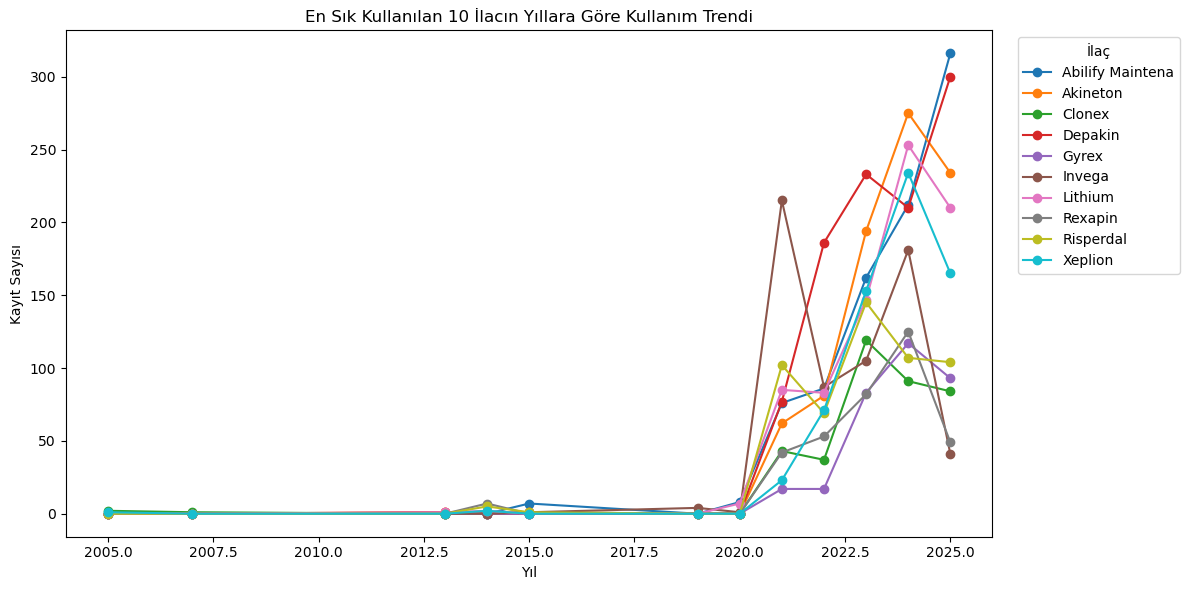

ilac_adi_normalize,Abilify Maintena,Akineton,Clonex,Depakin,Gyrex,Invega,Lithium,Rexapin,Risperdal,Xeplion
yil,,,,,,,,,,
2005,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2007,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2013,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2014,0.0,1.0,0.0,0.0,0.0,0.0,2.0,7.0,5.0,2.0
2015,7.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2019,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0
2020,8.0,0.0,0.0,0.0,0.0,1.0,7.0,0.0,0.0,0.0
2021,76.0,62.0,43.0,77.0,17.0,215.0,85.0,42.0,102.0,23.0
2022,86.0,81.0,37.0,186.0,17.0,87.0,83.0,53.0,69.0,71.0


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

pivot = (
    yillik_sayim[yillik_sayim["ilac_adi_normalize"].isin(en_sik_10)]
    .pivot(index="yil", columns="ilac_adi_normalize", values="sayi")
    .fillna(0)
)

fig, ax = plt.subplots(figsize=(12, 6))
pivot.plot(ax=ax, marker="o")
ax.set_xlabel("Yıl")
ax.set_ylabel("Kayıt Sayısı")
ax.set_title("En Sık Kullanılan 10 İlacın Yıllara Göre Kullanım Trendi")
ax.legend(title="İlaç", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("ilac_kullanim_trendi.png", dpi=150)
plt.show()

pivot

## 5. Özet

In [5]:
print("=== Özet ===")
print(f"Veritabanındaki toplam ilaç kaydı: {toplam_kayit}")
print(f"Güven eşiği (>= {GUVEN_ESIGI}) altında filtrelenen kayıt: {dusuk_guvenli_sayisi}")
print(f"Tarihsiz kayıt (analiz dışı bırakıldı): {tarihsiz_sayisi}")
print(f"Analize dahil edilen kayıt: {len(df)}")
print(f"Kapsanan yıl aralığı: {df['yil'].min()} - {df['yil'].max()}")

=== Özet ===
Veritabanındaki toplam ilaç kaydı: 28209
Güven eşiği (>= 90) altında filtrelenen kayıt: 10110
Tarihsiz kayıt (analiz dışı bırakıldı): 8229
Analize dahil edilen kayıt: 9870
Kapsanan yıl aralığı: 2005 - 2025
